In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:

df = pd.read_csv("Unemployment in India.csv")

df.head()



,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [3]:

print("Dataset shape:")
print(df.shape)

print("Column names:")
print(df.columns)

print("Missing values:")
print(df.isnull().sum())


Dataset shape:
(768, 7)
Column names:
Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='str')
Missing values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


In [4]:

df.columns = df.columns.str.strip()

print(df.columns)


Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='str')


In [5]:

df[df.isnull().all(axis=1)]


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

df = df.dropna(how="all")

print(df.shape)


(740, 7)


In [7]:

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

print(df["Date"].head())


0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[us]


In [8]:

print(df.isnull().sum())


Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [9]:

df.describe()


,Date,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


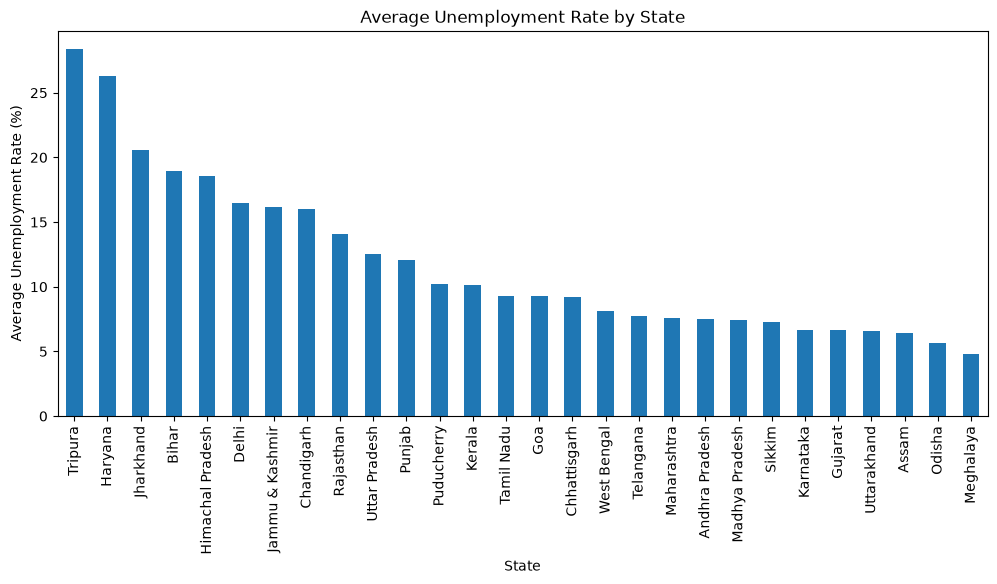

In [10]:

state_rate = df.groupby("Region")["Estimated Unemployment Rate (%)"].mean()

state_rate = state_rate.sort_values(ascending=False)

state_rate.plot(kind="bar", figsize=(12, 5))

plt.title("Average Unemployment Rate by State")
plt.xlabel("State")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=90)
plt.show()


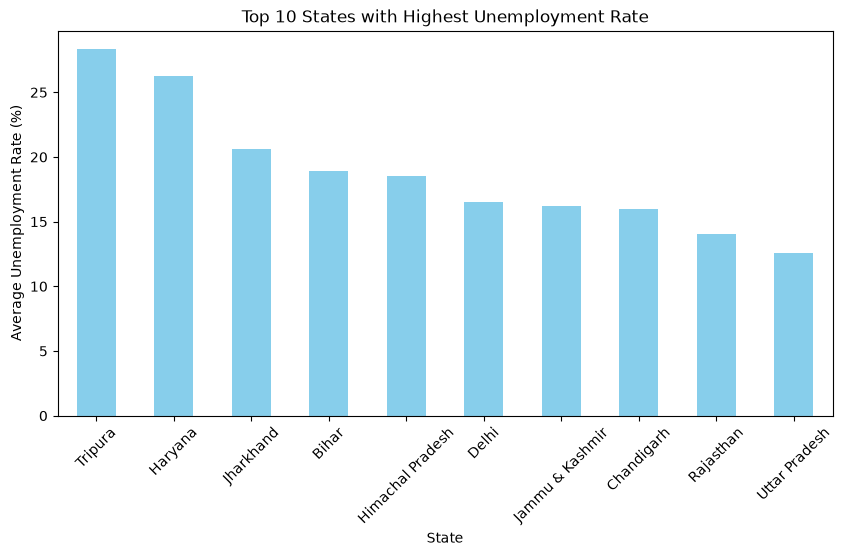

In [11]:

top_10 = state_rate.head(10)

top_10.plot(kind="bar", color="skyblue", figsize=(10, 5))

plt.title("Top 10 States with Highest Unemployment Rate")
plt.xlabel("State")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.show()


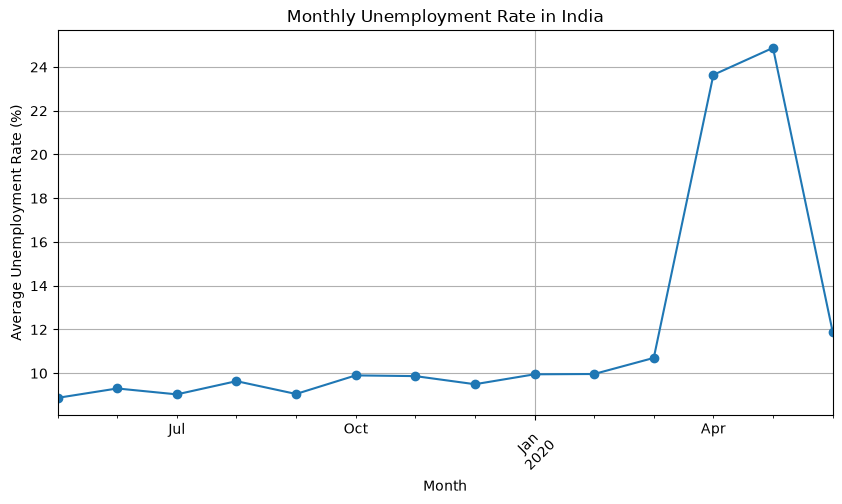

In [12]:

df["Month"] = df["Date"].dt.to_period("M")

monthly_rate = df.groupby("Month")["Estimated Unemployment Rate (%)"].mean()

monthly_rate.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid()
plt.show()


In [13]:

before_covid = df[df["Date"] < "2020-03-01"]
covid_period = df[df["Date"] >= "2020-03-01"]

before_rate = before_covid["Estimated Unemployment Rate (%)"].mean()
covid_rate = covid_period["Estimated Unemployment Rate (%)"].mean()

print("Average unemployment rate before COVID:", round(before_rate, 2), "%")
print("Average unemployment rate during COVID period:", round(covid_rate, 2), "%")


Average unemployment rate before COVID: 9.51 %
Average unemployment rate during COVID period: 17.77 %


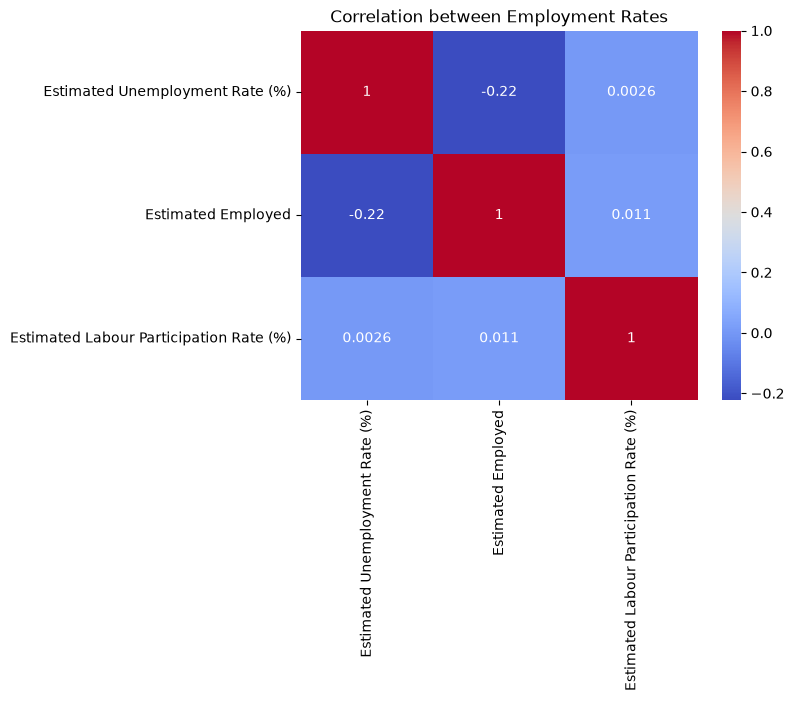

In [14]:

rates = df[[
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]]

correlation = rates.corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Correlation between Employment Rates")
plt.show()


In [18]:

print("OBSERVATIONS")
print("- The dataset contains unemployment information for different regions in India.")
print("- The average unemployment rate varies from state to state.")
print("- The monthly graph shows changes in unemployment over time.")
print("- The COVID-period unemployment rate can be compared with the pre-COVID rate.")
print("- The heatmap shows relationships between unemployment, employment and labour participation.")

print("\nCONCLUSION")
print("This project helped me analyse unemployment data using Python, Pandas, Matplotlib and Seaborn.")


OBSERVATIONS
- The dataset contains unemployment information for different regions in India.
- The average unemployment rate varies from state to state.
- The monthly graph shows changes in unemployment over time.
- The COVID-period unemployment rate can be compared with the pre-COVID rate.
- The heatmap shows relationships between unemployment, employment and labour participation.

CONCLUSION
This project helped me analyse unemployment data using Python, Pandas, Matplotlib and Seaborn.


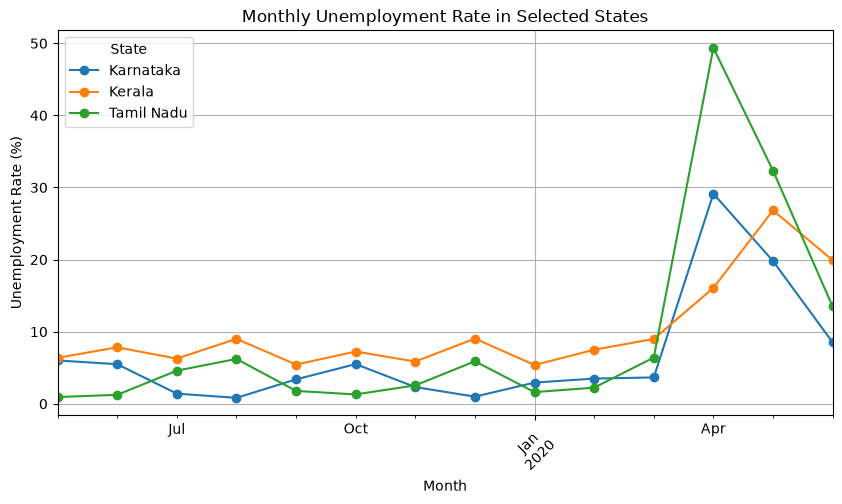

In [19]:

states = ["Tamil Nadu", "Kerala", "Karnataka"]

state_data = df[df["Region"].isin(states)]

monthly_states = state_data.groupby(
    [state_data["Date"].dt.to_period("M"), "Region"]
)["Estimated Unemployment Rate (%)"].mean().unstack()

monthly_states.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Unemployment Rate in Selected States")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="State")
plt.grid()
plt.show()
